In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [3]:
df = pd.read_csv("../data/water_potability.csv")

print("Dataset shape:", df.shape)

Dataset shape: (3276, 10)


In [4]:
X = df.drop(columns=["Potability"])
y = df["Potability"]

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [6]:
classifier = DecisionTreeClassifier(
    random_state=42
)

In [7]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", classifier)
])

In [8]:
model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [9]:
y_pred = model.predict(X_test)

In [10]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

print("\nDecision Tree Evaluation")
print("------------------------")

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)


Decision Tree Evaluation
------------------------
Accuracy : 0.5960365853658537
Precision: 0.48132780082987553
Recall   : 0.453125
F1 Score : 0.46680080482897385


In [11]:
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)


Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.69      0.67       400
           1       0.48      0.45      0.47       256

    accuracy                           0.60       656
   macro avg       0.57      0.57      0.57       656
weighted avg       0.59      0.60      0.59       656



In [12]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print("\nConfusion Matrix:")
print(cm)


Confusion Matrix:
[[275 125]
 [140 116]]


In [13]:
tree_model = model.named_steps["classifier"]

In [14]:
importance = tree_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("\nFeature Importance:")
print(feature_importance)


Feature Importance:
           Feature  Importance
2           Solids    0.137007
0               ph    0.136975
4          Sulfate    0.136640
3      Chloramines    0.125615
1         Hardness    0.116867
8        Turbidity    0.105770
7  Trihalomethanes    0.103627
5     Conductivity    0.069003
6   Organic_carbon    0.068497


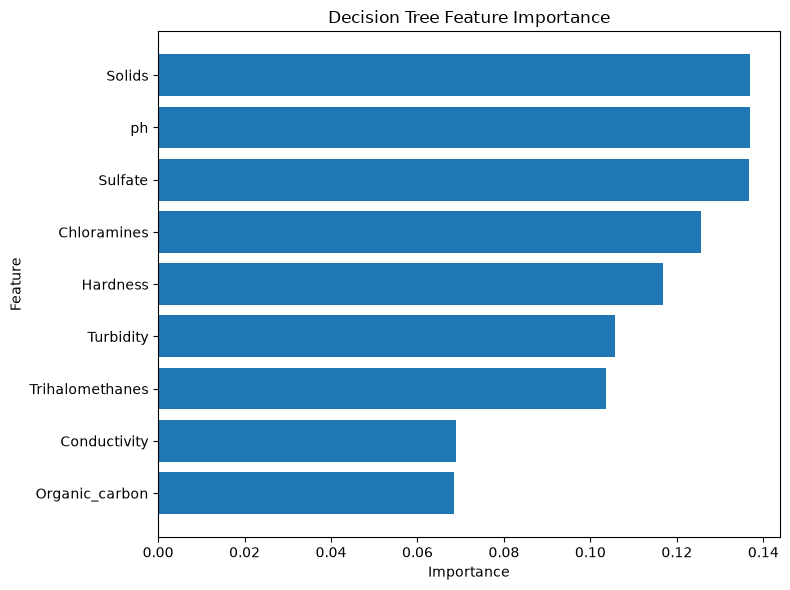

In [15]:
plt.figure(figsize=(8, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Decision Tree Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [16]:
probabilities = model.predict_proba(X_test)

print("\nFirst 5 probabilities:")
print(probabilities[:5])


First 5 probabilities:
[[0. 1.]
 [1. 0.]
 [0. 1.]
 [1. 0.]
 [0. 1.]]
